<a href="https://colab.research.google.com/github/nilesh426/CSL701-42_Machine-Learning-Lab/blob/main/Experiments/ML_EXP10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name : Nilesh Ashok Sawant

Roll_No: CE42

Batch: CE3

### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import urllib.request

# Download the dataset directly from a public source
url = 'https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv'
urllib.request.urlretrieve(url, 'Mall_Customers.csv')

# Load the dataset
df = pd.read_csv('Mall_Customers.csv')
display(df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:
# Select target features
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Verify scaling by printing mean and standard deviation
print(f"Scaled features mean: {X_scaled.mean(axis=0)}")
print(f"Scaled features standard deviation: {X_scaled.std(axis=0)}")

Scaled features mean: [-2.13162821e-16 -1.46549439e-16]
Scaled features standard deviation: [1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

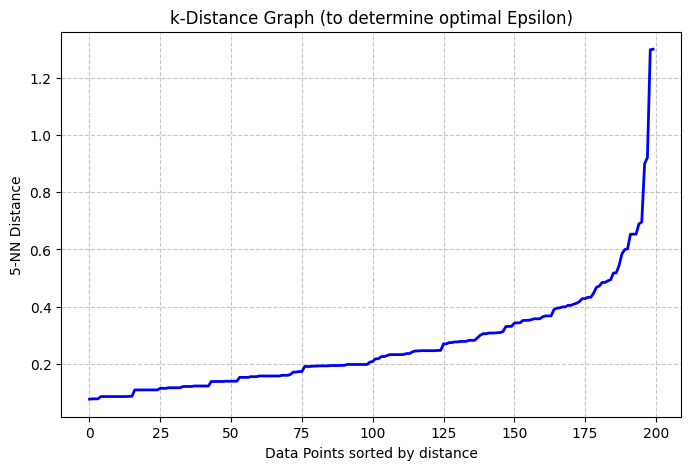

In [ ]:
# We will use min_samples = 5. Hence, we find the 5th nearest neighbors.
min_samples = 5

# Instantiate and fit NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort distance to the 5th nearest neighbor
sorted_distances = np.sort(distances[:, min_samples - 1])

# Plot the sorted k-distances
plt.figure(figsize=(8, 5))
plt.plot(sorted_distances, color='blue', lw=2)
plt.title('k-Distance Graph (to determine optimal Epsilon)')
plt.xlabel('Data Points sorted by distance')
plt.ylabel(f'{min_samples}-NN Distance')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:
# Based on the elbow plot, we select an optimal epsilon value
eps_val = 0.35
min_samples_val = 5

# Instantiate and fit DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
dbscan.fit(X_scaled)

# Extract and print cluster labels
labels = dbscan.labels_
print("Cluster labels assigned:\n", set(labels))

Cluster labels assigned:
 {np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(-1)}


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:
# Calculate the number of clusters (excluding noise points labeled -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

# Calculate Silhouette Score for non-noise points
# (Silhouette score is not defined for noise points as a separate cluster or for a single cluster)
if n_clusters > 1:
    non_noise_mask = labels != -1
    score = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
else:
    score = None

print(f"Estimated number of clusters: {n_clusters}")
print(f"Estimated number of noise points: {n_noise} (out of {len(X_scaled)} samples)")
if score is not None:
    print(f"Silhouette Score (excluding noise): {score:.4f}")
else:
    print("Silhouette Score: Not defined (less than 2 clusters found)")

Estimated number of clusters: 6
Estimated number of noise points: 23 (out of 200 samples)
Silhouette Score (excluding noise): 0.5577


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster Statistics and Demographics:


,Mean Annual Income (k$),Customer Count,Mean Spending Score (1-100)
Cluster_Label,,,
-1,89.260870,23,57.826087
0,24.750000,16,75.375000
1,24.583333,12,9.583333
2,22.428571,7,34.428571
3,55.227273,88,48.579545
4,80.290323,31,83.193548
5,80.956522,23,12.782609


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.